# EDA 1 — UCI Bike Sharing (UCI 275)
**Nguồn:** https://archive.ics.uci.edu/dataset/275 · **License:** CC BY 4.0 · **Paper gốc:** Fanaee-T & Gama (2014), *Event labeling combining ensemble detectors and background knowledge*, Progress in Artificial Intelligence 2(2–3):113–127, DOI 10.1007/s13748-013-0040-3.

Một chuỗi số lượt thuê xe theo giờ (Capital Bikeshare, Washington DC, 2011–2012), kèm thời tiết và lịch. Mục tiêu: `cnt`.

> Cách đọc: mỗi phần có ô code, rồi ô **Nhận xét** in ra từ chính số liệu vừa tính (không gõ tay số).

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from eda_utils import *
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 80
RAW = ROOT / 'data' / 'raw'
SUMMARY = {}  # các số chính, lưu ra reports/ để notebook so sánh dùng lại

## 1. Đọc dữ liệu, shape, kiểu

In [2]:
df = pd.read_csv(RAW/'hour.csv')
df['t'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], 'h')
print('shape:', df.shape); display(df.head(3)); display(overview(df))
SUMMARY.update(dataset='bike', rows=len(df), cols=df.shape[1]-1, freq='giờ', n_series=1)

shape: (17379, 18)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,t
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00


,dtype,n_missing,pct_missing,n_unique
instant,int64,0,0.0,17379
dteday,str,0,0.0,731
season,int64,0,0.0,4
yr,int64,0,0.0,2
mnth,int64,0,0.0,12
hr,int64,0,0.0,24
holiday,int64,0,0.0,2
weekday,int64,0,0.0,7
workingday,int64,0,0.0,2
weathersit,int64,0,0.0,4


## 2. Khoảng thời gian, giờ thiếu, trùng lặp

In [3]:
g, missing = time_gaps(df['t'], 'h'); display(pd.Series(g))
miss_by_day = pd.Series(missing.date).value_counts()
print('Số ngày có giờ thiếu:', len(miss_by_day), '| ngày thiếu nhiều nhất:'); display(miss_by_day.head(5))
print('Dòng trùng hoàn toàn:', df.duplicated().sum(), '| NA tổng:', df.isna().sum().sum())
SUMMARY.update(start=g['start'], end=g['end'], missing_steps=g['n_missing_steps'], dup_ts=g['n_duplicated_ts'], n_na=int(df.isna().sum().sum()))

start              2011-01-01 00:00:00
end                2012-12-31 23:00:00
n_expected                       17544
n_unique                         17379
n_missing_steps                    165
n_duplicated_ts                      0
dtype: object

Số ngày có giờ thiếu: 76 | ngày thiếu nhiều nhất:


2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
Name: count, dtype: int64

Dòng trùng hoàn toàn: 0 | NA tổng: 0


In [4]:
print(f"Nhận xét: {g['n_missing_steps']} giờ thiếu trên {g['n_expected']} giờ kỳ vọng ({100*g['n_missing_steps']/g['n_expected']:.2f}%), "
      f"rải trên {len(miss_by_day)} ngày; ngày thiếu nhiều nhất {miss_by_day.index[0]} ({miss_by_day.iloc[0]} giờ). "
      f"Không có NA trong ô. Giờ thiếu thường là giờ không có lượt thuê/sự cố hệ thống → khi dựng lưới đều cần quyết định điền 0 hay nội suy.")

Nhận xét: 165 giờ thiếu trên 17544 giờ kỳ vọng (0.94%), rải trên 76 ngày; ngày thiếu nhiều nhất 2012-10-29 (23 giờ). Không có NA trong ô. Giờ thiếu thường là giờ không có lượt thuê/sự cố hệ thống → khi dựng lưới đều cần quyết định điền 0 hay nội suy.


## 3. Rò rỉ dữ liệu: `casual + registered = cnt`

In [5]:
leak = (df.casual + df.registered == df.cnt).mean()
print(f'Tỉ lệ dòng có casual+registered==cnt: {leak:.4f}')
print('Tương quan với cnt:', df[['casual','registered']].corrwith(df.cnt).round(3).to_dict())
SUMMARY['leak_cols'] = 'casual, registered'

Tỉ lệ dòng có casual+registered==cnt: 1.0000
Tương quan với cnt: {'casual': 0.695, 'registered': 0.972}


In [6]:
print(f"Nhận xét: {leak*100:.1f}% dòng thoả casual+registered=cnt → hai cột này là THÀNH PHẦN của mục tiêu, "
      "phải BỎ khỏi đặc trưng (nếu không, mô hình 'nhìn thấy đáp án'). Tương tự `instant` chỉ là số thứ tự, `dteday` đã mã hoá thành t.")

Nhận xét: 100.0% dòng thoả casual+registered=cnt → hai cột này là THÀNH PHẦN của mục tiêu, phải BỎ khỏi đặc trưng (nếu không, mô hình 'nhìn thấy đáp án'). Tương tự `instant` chỉ là số thứ tự, `dteday` đã mã hoá thành t.


## 4. Thống kê mô tả, phân phối, độ lệch

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
cnt,17379.0,189.463,181.388,1.00,40.000,142.000,281.000,977.000,1.277,1.417
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000,-0.006,-0.942
atemp,17379.0,0.476,0.172,0.00,0.333,0.485,0.621,1.000,-0.090,-0.845
hum,17379.0,0.627,0.193,0.00,0.480,0.630,0.780,1.000,-0.111,-0.826
windspeed,17379.0,0.190,0.122,0.00,0.104,0.194,0.254,0.851,0.575,0.591


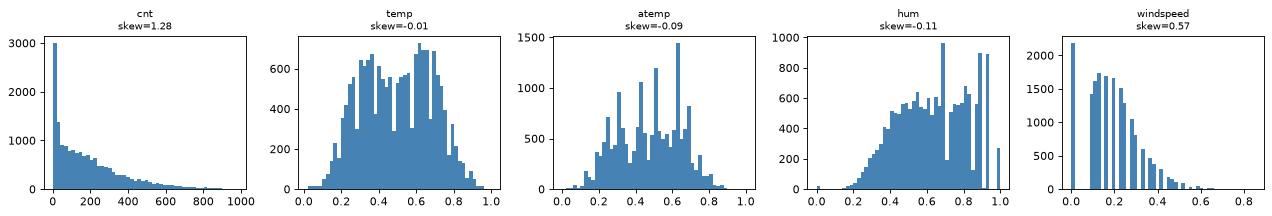

skew của log1p(cnt): -0.818


In [7]:
num = ['cnt','temp','atemp','hum','windspeed']
st = shape_stats(df[num]); display(st); plot_dists(df, num)
SUMMARY.update(target_mean=st.loc['cnt','mean'], target_skew=st.loc['cnt','skew'], target_kurt=st.loc['cnt','kurtosis'],
               target_cv=round(st.loc['cnt','std']/st.loc['cnt','mean'],3))
print('skew của log1p(cnt):', round(np.log1p(df.cnt).skew(),3))

In [8]:
print(f"Nhận xét: cnt trung bình {st.loc['cnt','mean']:.1f}, trung vị {st.loc['cnt','50%']:.0f}, max {st.loc['cnt','max']:.0f}; "
      f"skew={st.loc['cnt','skew']:.2f}, kurtosis={st.loc['cnt','kurtosis']:.2f} → lệch phải. log1p đưa skew về {np.log1p(df.cnt).skew():.2f}. "
      "temp/atemp/hum/windspeed đã chuẩn hoá về [0,1] bởi nhà cung cấp.")

Nhận xét: cnt trung bình 189.5, trung vị 142, max 977; skew=1.28, kurtosis=1.42 → lệch phải. log1p đưa skew về -0.82. temp/atemp/hum/windspeed đã chuẩn hoá về [0,1] bởi nhà cung cấp.


## 5. Outlier (IQR 1.5)

In [9]:
out = iqr_outliers(df[num]); display(out)
SUMMARY['target_outlier_pct'] = out.loc['cnt','pct']
print(f"Nhận xét: {int(out.loc['cnt','n_outliers'])} giờ ({out.loc['cnt','pct']}%) có cnt vượt ngưỡng IQR {out.loc['cnt','upper']:.0f}; "
      "đây chủ yếu là giờ cao điểm thật, không phải lỗi → không nên xoá, cân nhắc biến đổi log.")

,lower,upper,n_outliers,pct
cnt,-321.50000,642.50000,505.0,2.906
temp,-0.14000,1.14000,0.0,0.000
atemp,-0.09855,1.05305,0.0,0.000
hum,0.03000,1.23000,22.0,0.127
windspeed,-0.11930,0.47750,342.0,1.968


Nhận xét: 505 giờ (2.906%) có cnt vượt ngưỡng IQR 642; đây chủ yếu là giờ cao điểm thật, không phải lỗi → không nên xoá, cân nhắc biến đổi log.


## 6. Xu hướng & mùa vụ

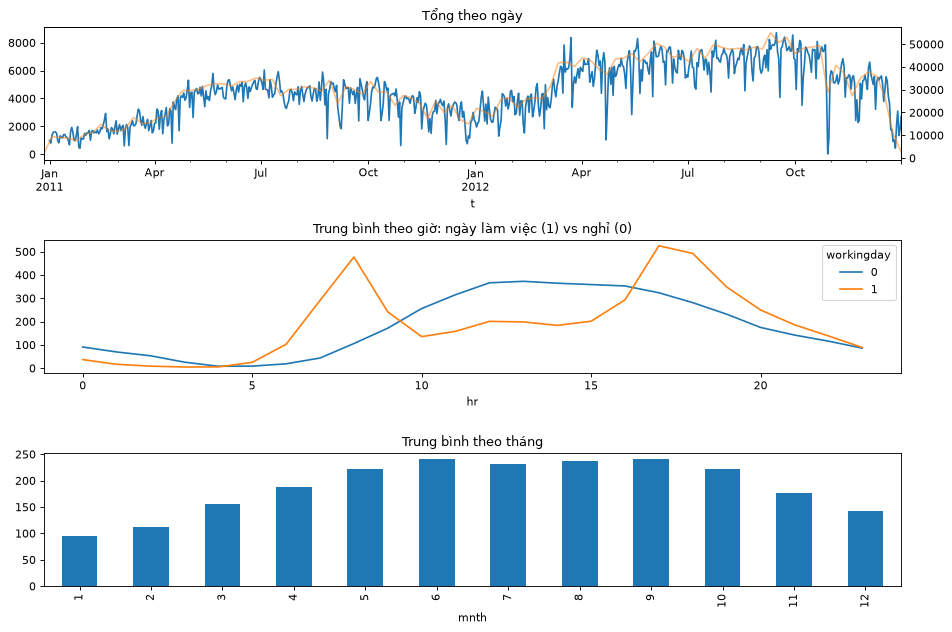

TB/giờ theo năm: {0: 143.8, 1: 234.7} | tăng 63.2%


In [10]:
s = df.set_index('t')['cnt']
fig, ax = plt.subplots(3,1, figsize=(12,8))
s.resample('D').sum().plot(ax=ax[0], title='Tổng theo ngày'); s.resample('W').sum().plot(ax=ax[0], secondary_y=True, alpha=.5)
df.groupby(['workingday','hr']).cnt.mean().unstack(0).plot(ax=ax[1], title='Trung bình theo giờ: ngày làm việc (1) vs nghỉ (0)')
df.groupby('mnth').cnt.mean().plot.bar(ax=ax[2], title='Trung bình theo tháng'); plt.tight_layout(); plt.show()
yr = df.groupby('yr').cnt.mean(); growth = yr[1]/yr[0]-1
print('TB/giờ theo năm:', yr.round(1).to_dict(), f'| tăng {growth*100:.1f}%')
SUMMARY['yoy_growth_pct'] = round(growth*100,1)

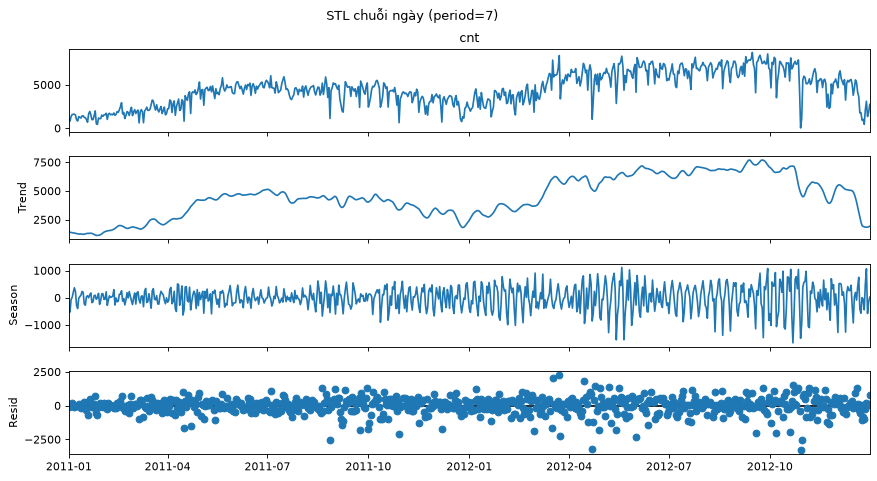

STL ngày (mùa tuần): {'trend_strength': np.float64(0.889), 'seasonal_strength': np.float64(0.393)} | STL giờ (mùa ngày): {'trend_strength': np.float64(0.676), 'seasonal_strength': np.float64(0.881)}


In [11]:
sd = s.resample('D').sum()
strength_w = stl_strength(sd, period=7, title='STL chuỗi ngày (period=7)')
sh = s.asfreq('h').interpolate()  # chỉ cho STL; không dùng để huấn luyện
strength_d = stl_strength(sh, period=24, plot=False)
print('STL ngày (mùa tuần):', strength_w, '| STL giờ (mùa ngày):', strength_d)
SUMMARY.update(trend_strength=strength_w['trend_strength'], seasonal_strength=strength_d['seasonal_strength'])

In [12]:
pk = df.groupby(['workingday','hr']).cnt.mean()
print(f"Nhận xét: TB/giờ năm 2012 cao hơn 2011 {growth*100:.1f}% → xu hướng tăng rõ (phân phối trôi theo thời gian). "
      f"Ngày làm việc: đỉnh sáng giờ {pk[1].loc[:11].idxmax()} ({pk[1].loc[:11].max():.0f}), đỉnh chiều giờ {pk[1].loc[12:].idxmax()} ({pk[1].loc[12:].max():.0f}); ngày nghỉ đỉnh giờ {pk[0].idxmax()} ({pk[0].max():.0f}). "
      f"Độ mạnh mùa ngày (STL period=24) = {strength_d['seasonal_strength']}, độ mạnh xu hướng chuỗi ngày = {strength_w['trend_strength']}.")

Nhận xét: TB/giờ năm 2012 cao hơn 2011 63.2% → xu hướng tăng rõ (phân phối trôi theo thời gian). Ngày làm việc: đỉnh sáng giờ 8 (477), đỉnh chiều giờ 17 (525); ngày nghỉ đỉnh giờ 13 (373). Độ mạnh mùa ngày (STL period=24) = 0.881, độ mạnh xu hướng chuỗi ngày = 0.889.


## 7. ACF/PACF

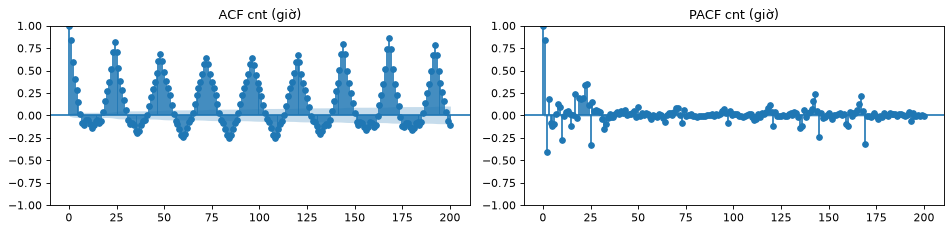

{'lag1': np.float64(0.843), 'lag2': np.float64(0.592), 'lag24': np.float64(0.819), 'lag168': np.float64(0.876)}
Nhận xét: tự tương quan lag1=0.843, lag24=0.819, lag168=0.876 → mùa ngày và tuần rõ; đặc trưng lag 24/168 hữu ích.


In [13]:
acf_pacf(sh, lags=200, title='cnt (giờ)')
ac = autocorrs(s.asfreq('h'), [1,2,24,168]); print(ac); SUMMARY['acf'] = ac
print(f"Nhận xét: tự tương quan lag1={ac['lag1']}, lag24={ac['lag24']}, lag168={ac['lag168']} → mùa ngày và tuần rõ; đặc trưng lag 24/168 hữu ích.")

## 8. Kiểm định dừng (ADF / KPSS)
ADF: H0 = không dừng. KPSS: H0 = dừng. p-value của KPSS bị statsmodels chặn trong [0.01, 0.1].

In [14]:
res = pd.DataFrame([stationarity(sh, 'cnt giờ'), stationarity(sd, 'cnt ngày'), stationarity(sd.diff(), 'cnt ngày, sai phân 1')]); display(res)
SUMMARY['stationarity'] = res.set_index('series')['kết luận'].to_dict()

,series,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p(bị chặn 0.01-0.1),kết luận
0,cnt giờ,17544,-6.944,0.0000,19.405,0.01,"trái chiều: ADF nói dừng, KPSS nói không dừng ..."
1,cnt ngày,731,-1.877,0.3427,2.424,0.01,không dừng
2,"cnt ngày, sai phân 1",730,-11.779,0.0000,0.226,0.10,dừng


In [15]:
print('Nhận xét:', '; '.join(f"{r.series}: ADF p={r.ADF_p}, KPSS p={r['KPSS_p(bị chặn 0.01-0.1)']} → {r['kết luận']}" for _, r in res.iterrows()))

Nhận xét: cnt giờ: ADF p=0.0, KPSS p=0.01 → trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân); cnt ngày: ADF p=0.3427, KPSS p=0.01 → không dừng; cnt ngày, sai phân 1: ADF p=0.0, KPSS p=0.1 → dừng


## 9. Tương quan với biến ngoại sinh

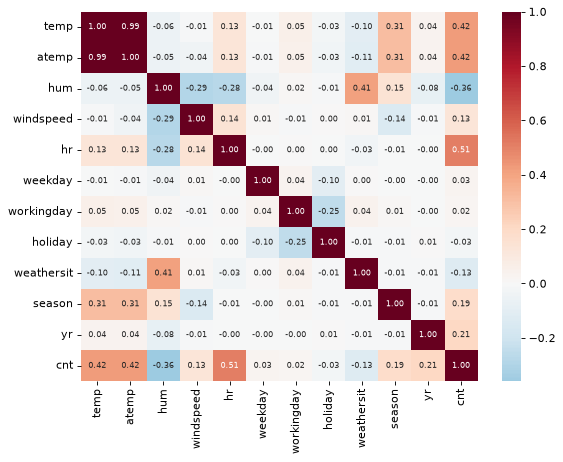

hr            0.511
temp          0.423
atemp         0.423
hum          -0.360
yr            0.207
season        0.185
windspeed     0.127
weathersit   -0.126
weekday       0.030
holiday      -0.030
workingday    0.021
Name: cnt, dtype: float64

Tương quan temp–atemp: 0.988


In [16]:
ex = ['temp','atemp','hum','windspeed','hr','weekday','workingday','holiday','weathersit','season','yr']
corr = df[ex+['cnt']].corr(method='spearman')
plt.figure(figsize=(8,6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size':7}); plt.show()
c = corr['cnt'].drop('cnt').sort_values(key=abs, ascending=False); display(c.round(3))
print('Tương quan temp–atemp:', round(df.temp.corr(df.atemp),3))
SUMMARY['top_exog'] = c.round(3).head(3).to_dict()

In [17]:
print(f"Nhận xét: biến tương quan (Spearman) mạnh nhất với cnt: {', '.join(f'{k}={v:.2f}' for k,v in c.head(4).items())}. "
      f"temp và atemp gần trùng (r={df.temp.corr(df.atemp):.3f}) → giữ một. Thời tiết là biến quan sát cùng thời điểm: khi dự báo nhiều bước cần dùng dự báo thời tiết hoặc lag.")

Nhận xét: biến tương quan (Spearman) mạnh nhất với cnt: hr=0.51, temp=0.42, atemp=0.42, hum=-0.36. temp và atemp gần trùng (r=0.988) → giữ một. Thời tiết là biến quan sát cùng thời điểm: khi dự báo nhiều bước cần dùng dự báo thời tiết hoặc lag.


In [18]:
import json; (ROOT/'reports').mkdir(exist_ok=True)
json.dump(SUMMARY, open(ROOT/'reports'/f"summary_{SUMMARY['dataset']}.json", 'w'), ensure_ascii=False, indent=1, default=str)
SUMMARY

{'dataset': 'bike',
 'rows': 17379,
 'cols': 17,
 'freq': 'giờ',
 'n_series': 1,
 'start': Timestamp('2011-01-01 00:00:00'),
 'end': Timestamp('2012-12-31 23:00:00'),
 'missing_steps': 165,
 'dup_ts': 0,
 'n_na': 0,
 'leak_cols': 'casual, registered',
 'target_mean': np.float64(189.463),
 'target_skew': np.float64(1.277),
 'target_kurt': np.float64(1.417),
 'target_cv': np.float64(0.957),
 'target_outlier_pct': np.float64(2.906),
 'yoy_growth_pct': np.float64(63.2),
 'trend_strength': np.float64(0.889),
 'seasonal_strength': np.float64(0.881),
 'acf': {'lag1': np.float64(0.843),
  'lag2': np.float64(0.592),
  'lag24': np.float64(0.819),
  'lag168': np.float64(0.876)},
 'stationarity': {'cnt giờ': 'trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân)',
  'cnt ngày': 'không dừng',
  'cnt ngày, sai phân 1': 'dừng'},
 'top_exog': {'hr': 0.511, 'temp': 0.423, 'atemp': 0.423}}